# Mass-univariate screen of individual environmental items: split-half discovery and replication

This notebook screens individual baseline environmental items against the **NODDI + macrostructure** white-matter features independently in the ABCD discovery and replication halves. Both halves use the imaging file harmonized with respect to split A: `matched_group==1` is the discovery sample and `matched_group==2` is the replication sample. Split-specific FDR correction is performed independently within each environmental item across its 1,302 WM tests. A final section quantifies split-half concordance of the partial-r maps and overlap of FDR-significant item × WM-feature associations.


In [1]:
from pathlib import Path
import re
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from matplotlib.patches import Patch

pd.set_option("display.max_rows",100)
pd.set_option("display.max_columns",100)

ROOT_DIR=Path("/mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome")
INPUT_DIR=ROOT_DIR/"input_data"
RESULTS_DIR=ROOT_DIR/"output_data"/"results"
OUT_DIR=RESULTS_DIR/"reviewer_revision"/"individual_environment_items_split_half"
OUT_DIR.mkdir(parents=True,exist_ok=True)

# Both halves use the imaging data harmonized with respect to discovery split A.
IMAGING_FILE=RESULTS_DIR/"dfA_macro_plus_NODDI_12_10.csv"
ITEM_FILE=INPUT_DIR/"ABCD_to_send.csv"
QC_MAPPING_FILE=INPUT_DIR/"environmental_item_construct_ecological_qc_v3_final.csv"
BASELINE_EVENT="baseline_year_1_arm_1"

# ============================================================
# Split-half configuration
# Discovery uses dfA; Replication uses dfB
# ============================================================

SPLITS={
    "A":{
        "matched_group":1,
        "label":"Discovery",
        "imaging_file":RESULTS_DIR/"dfA_macro_plus_NODDI_12_10.csv"
    },
    "B":{
        "matched_group":2,
        "label":"Replication",
        "imaging_file":RESULTS_DIR/"dfB_macro_plus_NODDI_12_10.csv"
    }
}

SPLIT_DIRS={
    split:OUT_DIR/f"split_{split}"
    for split in SPLITS
}

for split_dir in SPLIT_DIRS.values():
    split_dir.mkdir(
        parents=True,
        exist_ok=True
    )

CONCORDANCE_DIR=OUT_DIR/"split_half_concordance"
CONCORDANCE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for split,cfg in SPLITS.items():
    print(
        f"Split {split}: "
        f"{cfg['label']}, "
        f"matched_group={cfg['matched_group']}"
    )
    print(
        "Imaging file:",
        cfg["imaging_file"]
    )


NUISANCE_COLS=["age","sex","t1post_dwi_contrast"]
GENERAL_EXPOSOME="General_SES"
MISSING_CODE=99999
MIN_N=100
SUMMARY_TOP_N=30
TOP_N_HEATMAPS=20
TOP_HEATMAP_RANK_BY="n_fdr_sig"  # change to "mean_abs_partial_r" if preferred

print("Imaging file:",IMAGING_FILE)
print("Item file:",ITEM_FILE)
print("QC mapping file:",QC_MAPPING_FILE)
print("Output:",OUT_DIR)
for split,cfg in SPLITS.items():
    print(f"Split {split}: {cfg['label']}, matched_group={cfg['matched_group']}")


Imaging file: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/dfA_macro_plus_NODDI_12_10.csv
Item file: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/input_data/ABCD_to_send.csv
QC mapping file: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/input_data/environmental_item_construct_ecological_qc_v3_final.csv
Output: /mnt/isilon/bgdlab_hbcd/projects/macedo_wm_exposome/macedo_wm_exposome/output_data/results/reviewer_revision/individual_environment_items_split_half
Split A: Discovery, matched_group=1
Split B: Replication, matched_group=2


## 1. Load A-harmonized imaging data and baseline environmental items


In [2]:
# Load only columns needed for this analysis to limit memory use.
keep_imaging=lambda c:(
    c.startswith("bundle_") or
    c in {"subject_id_clean","matched_group",GENERAL_EXPOSOME,*NUISANCE_COLS}
)

imaging_all=pd.read_csv(IMAGING_FILE,usecols=keep_imaging)

# Keep the median NODDI tract summaries and drop the duplicate mean versions.
# Macrostructural columns do not use these suffixes and are left unchanged.
mean_cols=[c for c in imaging_all.columns if c.startswith("bundle_") and c.endswith("_mean")]
median_cols=[c for c in imaging_all.columns if c.startswith("bundle_") and c.endswith("_median")]

if mean_cols:
    imaging_all.drop(columns=mean_cols,inplace=True)

rename_cols={c:c[:-len("_median")] for c in median_cols}
existing_after_drop=set(imaging_all.columns)-set(rename_cols)
collisions=set(rename_cols.values()) & existing_after_drop
if collisions:
    raise ValueError(f"Renaming *_median columns would overwrite existing columns: {sorted(collisions)[:10]}")
if rename_cols:
    imaging_all.rename(columns=rename_cols,inplace=True)

wm_cols=[c for c in imaging_all.columns if c.startswith("bundle_")]
print("Dropped *_mean WM columns:",len(mean_cols))
print("Kept/renamed *_median WM columns:",len(median_cols))
print("Full A-harmonized imaging shape:",imaging_all.shape)
print("WM features:",len(wm_cols))
assert len(wm_cols)==1302,f"Expected 1302 NODDI+macro WM features after median cleanup, found {len(wm_cols)}"

print("\nParticipants available by matched_group:")
print(imaging_all["matched_group"].value_counts(dropna=False).sort_index())

for split,cfg in SPLITS.items():
    n_split=imaging_all.loc[imaging_all["matched_group"]==cfg["matched_group"],"subject_id_clean"].nunique()
    print(f"Split {split} ({cfg['label']}): {n_split} unique participants")

exp_items=pd.read_csv(ITEM_FILE)
exp_items=exp_items.loc[exp_items["eventname"]==BASELINE_EVENT].copy()
exp_items["subject_id_clean"]=exp_items["src_subject_id"].astype(str).str.replace(r"^NDAR_INV","",regex=True)

# Stop rather than silently deduplicate.
dups=exp_items["subject_id_clean"].duplicated(keep=False)
if dups.any():
    display(exp_items.loc[dups,["src_subject_id","subject_id_clean","eventname"]].sort_values("subject_id_clean").head(30))
    raise ValueError(f"Found {dups.sum()} baseline rows belonging to duplicated subject IDs. Resolve before continuing.")

print("Baseline item rows:",len(exp_items))
print("Unique baseline subjects:",exp_items["subject_id_clean"].nunique())


Dropped *_mean WM columns: 186
Kept/renamed *_median WM columns: 186
Full A-harmonized imaging shape: (8180, 1308)
WM features: 1302

Participants available by matched_group:
matched_group
1    4081
2    4099
Name: count, dtype: int64
Split A (Discovery): 4081 unique participants
Split B (Replication): 4099 unique participants
Baseline item rows: 11872
Unique baseline subjects: 11872


## 2. Define candidate environmental variables once

In [3]:
# Metadata / identifiers / analysis bookkeeping that should not be treated as exposures.
EXCLUDE_COLS={
    "pid","src_subject_id","subject_id_clean","uid","eventname","interview_age","Male",
    "rel_family_id","site_id_l_br","tp","val","matched_group"
}

# Start with all remaining columns. Edit EXCLUDE_COLS or ITEM_VARS here if you want to narrow later.
ITEM_VARS=[c for c in exp_items.columns if c not in EXCLUDE_COLS]

print("Candidate item variables:",len(ITEM_VARS))
print(ITEM_VARS[:30])

# ABCD_to_send.csv uses 99999 as a missing-value sentinel for environmental variables.
# Convert only those environmental item columns to real NaN values. This does NOT
# globally drop subjects; each item-specific model later uses complete cases for that item.
missing_code_counts={}
for var in ITEM_VARS:
    x=pd.to_numeric(exp_items[var],errors="coerce")
    is_missing_code=x.eq(MISSING_CODE)
    missing_code_counts[var]=int(is_missing_code.sum())
    if is_missing_code.any():
        exp_items.loc[is_missing_code,var]=np.nan

missing_code_qc=(pd.DataFrame({
    "variable":ITEM_VARS,
    "n_99999_replaced":[missing_code_counts[v] for v in ITEM_VARS]
}).sort_values("n_99999_replaced",ascending=False).reset_index(drop=True))
missing_code_qc.to_csv(OUT_DIR/"item_99999_replacements.csv",index=False)

print(f"Total {MISSING_CODE} values replaced with NaN:",missing_code_qc["n_99999_replaced"].sum())
print("Variables containing at least one 99999:",(missing_code_qc["n_99999_replaced"]>0).sum())
display(missing_code_qc.loc[missing_code_qc["n_99999_replaced"]>0].head(30))

Candidate item variables: 291
['parent_ses', 'separated_or_divorced', 'parents_married', 'living_with_partenr_or_married', 'prnts_edu', 'hshld_inc', 'demo_fam_poverty', 'school_2_y', 'school_3_y', 'school_4_y', 'school_5_y', 'school_6_y', 'school_7_y', 'school_8_y', 'school_9_y', 'school_10_y', 'school_12_y', 'school_15_y', 'school_17_y', 'fes_youth_q1', 'fes_youth_q2', 'fes_youth_q3', 'fes_youth_q4', 'fes_youth_q5', 'fes_youth_q6', 'fes_youth_q7', 'fes_youth_q8', 'fes_youth_q9', 'fam_enviro1_p', 'fam_enviro2r_p']
Total 99999 values replaced with NaN: 137787
Variables containing at least one 99999: 291


,variable,n_99999_replaced
0,reshist_addr1_scanweektemp_t0,3839
1,reshist_addr1_scanweekvpd_t6,3296
2,reshist_addr1_scanweekvpd_t5,3296
3,reshist_addr1_scanweekvpd_t1,3296
4,reshist_addr1_scanweekvpd_t2,3296
5,reshist_addr1_scanweekvpd_t3,3296
6,reshist_addr1_scanweekvpd_t0,3296
7,reshist_addr1_scanweekvpd_t4,3296
8,addr_dry_heat,3296
9,reshist_addr1_svi_grp_20142018,1142


## 2b. Final construct and ecological-level mapping

The finalized QC table is the **only source of category labels used for downstream summaries and plots**. 

In [4]:
if not QC_MAPPING_FILE.exists():
    raise FileNotFoundError(f"Final QC mapping file not found: {QC_MAPPING_FILE}")

qc_map=pd.read_csv(QC_MAPPING_FILE)
required_qc_cols=["variable","construct_category","ecological_level"]
missing_qc_cols=[c for c in required_qc_cols if c not in qc_map.columns]
if missing_qc_cols:
    raise ValueError(f"QC mapping is missing required columns: {missing_qc_cols}")
if qc_map["variable"].duplicated().any():
    dupes=qc_map.loc[qc_map["variable"].duplicated(keep=False),"variable"].tolist()
    raise ValueError(f"Duplicate variables in QC mapping: {dupes[:20]}")

qc_map=qc_map.copy()
qc_map["construct_category"]=qc_map["construct_category"].astype("string").str.strip()
qc_map["ecological_level"]=qc_map["ecological_level"].astype("string").str.strip()
qc_final=qc_map.loc[qc_map["construct_category"].ne("Needs clarification")].copy()
needs_clarification=qc_map.loc[qc_map["construct_category"].eq("Needs clarification")].copy()

print("QC variables total:",len(qc_map))
print("Excluded as Needs clarification:",len(needs_clarification))
print("QC variables retained:",len(qc_final))
if len(needs_clarification):
    display(needs_clarification[["variable","construct_category","ecological_level","description"]])

CONSTRUCT_ORDER=[
    "Socioeconomic & opportunity context","Family environment","Parenting","Culture & values",
    "School environment","Neighborhood & built environment","Physical environment",
    "Policy & structural context","Activities & enrichment","Screen & digital environment",
    "Substance-use environment","Health / developmental history"
]
ECOLOGICAL_ORDER=["Individual","Family/household","School","Peer/social","Neighborhood/community","State/policy"]

unexpected_construct=sorted(set(qc_final["construct_category"].dropna())-set(CONSTRUCT_ORDER))
unexpected_eco=sorted(set(qc_final["ecological_level"].dropna())-set(ECOLOGICAL_ORDER))
print("Unexpected construct categories:",unexpected_construct if unexpected_construct else "None")
print("Unexpected ecological levels:",unexpected_eco if unexpected_eco else "None")
assert not unexpected_construct,"QC mapping contains construct categories not in CONSTRUCT_ORDER."
assert not unexpected_eco,"QC mapping contains ecological levels not in ECOLOGICAL_ORDER."

# Explicit high-contrast colors: one hue per category, no paired light/dark shades.
CONSTRUCT_COLORS=[
    "#1f77b4","#d62728","#ff7f0e","#9467bd","#2ca02c","#8c564b",
    "#17becf","#e377c2","#bcbd22","#7f3c8d","#1b9e77","#4d4d4d"
]
construct_order=[c for c in CONSTRUCT_ORDER if c in set(qc_final["construct_category"].dropna())]
construct_palette=dict(zip(construct_order,[CONSTRUCT_COLORS[CONSTRUCT_ORDER.index(c)] for c in construct_order]))
ecological_colors=["#1b9e77","#d95f02","#7570b3","#e7298a","#66a61e","#e6ab02"]
ecological_order=[c for c in ECOLOGICAL_ORDER if c in set(qc_final["ecological_level"].dropna())]
ecological_palette=dict(zip(ecological_order,[ecological_colors[ECOLOGICAL_ORDER.index(c)] for c in ecological_order]))
construct_handles=[Patch(facecolor=construct_palette[c],label=c) for c in construct_order]

print("\nConstruct-category counts:")
display(qc_final["construct_category"].value_counts().reindex(construct_order).rename("n").to_frame())
print("\nEcological-level counts:")
display(qc_final["ecological_level"].value_counts().reindex(ecological_order).rename("n").to_frame())
print("\nConstruct x ecological level:")
display(pd.crosstab(qc_final["construct_category"],qc_final["ecological_level"]).reindex(index=construct_order,columns=ecological_order,fill_value=0))


QC variables total: 291
Excluded as Needs clarification: 0
QC variables retained: 291
Unexpected construct categories: None
Unexpected ecological levels: None

Construct-category counts:


,n
construct_category,
Socioeconomic & opportunity context,59
Family environment,25
Parenting,10
Culture & values,36
School environment,16
Neighborhood & built environment,14
Physical environment,30
Policy & structural context,5
Activities & enrichment,35



Ecological-level counts:


,n
ecological_level,
Individual,85
Family/household,73
School,16
Peer/social,7
Neighborhood/community,105
State/policy,5



Construct x ecological level:


ecological_level,Individual,Family/household,School,Peer/social,Neighborhood/community,State/policy
construct_category,,,,,,
Socioeconomic & opportunity context,0,4,0,0,55,0
Family environment,0,25,0,0,0,0
Parenting,0,10,0,0,0,0
Culture & values,2,34,0,0,0,0
School environment,0,0,16,0,0,0
Neighborhood & built environment,0,0,0,0,14,0
Physical environment,0,0,0,0,30,0
Policy & structural context,0,0,0,0,0,5
Activities & enrichment,35,0,0,0,0,0


## 3. Missingness and simple numeric-type summary

Here, `continuous_like` only means that the observed numeric column contains at least one non-integer value. `integer_or_binary` means all observed numeric values are integer-valued. This is a descriptive coding check, not a semantic claim about whether a questionnaire scale is truly continuous or ordinal.

In [5]:
def classify_numeric_column(s):
    x=pd.to_numeric(s,errors="coerce")
    n_numeric=x.notna().sum()
    if n_numeric==0:
        return "non_numeric"
    vals=x.dropna().to_numpy(dtype=float)
    if len(vals)==0:
        return "non_numeric"
    if np.all(np.isclose(vals,np.round(vals))):
        return "integer_or_binary"
    return "continuous_like"

rows=[]
for var in ITEM_VARS:
    s=exp_items[var]
    numeric=pd.to_numeric(s,errors="coerce")
    rows.append({
        "variable":var,
        "type_simple":classify_numeric_column(s),
        "n_99999_replaced":missing_code_counts[var],
        "n_nonmissing":int(numeric.notna().sum()),
        "missing_pct":100*numeric.isna().mean(),
        "n_unique_numeric":int(numeric.nunique(dropna=True))
    })

item_qc=pd.DataFrame(rows)
item_qc.to_csv(OUT_DIR/"item_missingness_and_type_after_99999_cleanup.csv",index=False)

type_counts=item_qc["type_simple"].value_counts(dropna=False)
print("Variable-type summary after missing-code cleanup:")
for label,n in type_counts.items():
    print(f"  {label}: {n}/{len(item_qc)} ({100*n/len(item_qc):.1f}%)")

print("\nMissingness by variable after converting 99999 -> NaN:")
display(item_qc.sort_values("missing_pct",ascending=False).reset_index(drop=True))

Variable-type summary after missing-code cleanup:
  continuous_like: 177/291 (60.8%)
  integer_or_binary: 114/291 (39.2%)

Missingness by variable after converting 99999 -> NaN:


,variable,type_simple,n_99999_replaced,n_nonmissing,missing_pct,n_unique_numeric
0,reshist_addr1_scanweektemp_t0,continuous_like,3839,8033,32.336590,3649
1,reshist_addr1_scanweekvpd_t6,continuous_like,3296,8576,27.762803,7515
2,reshist_addr1_scanweekvpd_t5,continuous_like,3296,8576,27.762803,7524
3,reshist_addr1_scanweekvpd_t1,continuous_like,3296,8576,27.762803,7526
4,reshist_addr1_scanweekvpd_t2,continuous_like,3296,8576,27.762803,7520
...,...,...,...,...,...,...
286,fes_youth_q4,integer_or_binary,25,11847,0.210580,2
287,fes_youth_q3,integer_or_binary,25,11847,0.210580,2
288,fes_youth_q2,integer_or_binary,25,11847,0.210580,2
289,parent_ses,continuous_like,25,11847,0.210580,1287


## 4. Merge environmental items into discovery and replication imaging samples


In [6]:
merge_cols=["subject_id_clean"]+ITEM_VARS
analysis_dfs={}
imaging_sample_missingness_by_split={}

for split,cfg in SPLITS.items():
    print("\n"+"="*70)
    print(f"Preparing split {split}: {cfg['label']} (matched_group={cfg['matched_group']})")
    print("="*70)

    imaging_split=imaging_all.loc[
        imaging_all["matched_group"]==cfg["matched_group"]
    ].copy()

    analysis_df=imaging_split.merge(
        exp_items[merge_cols],
        on="subject_id_clean",
        how="left",
        validate="one_to_one"
    )

    print("Merged shape:",analysis_df.shape)
    print("Participants with any item data:",analysis_df[ITEM_VARS].notna().any(axis=1).sum())

    # Coerce nuisance variables and candidate items to numeric.
    if analysis_df["sex"].dtype==object:
        sex_map={"M":1,"Male":1,"male":1,"F":0,"Female":0,"female":0}
        analysis_df["sex"]=analysis_df["sex"].replace(sex_map)

    for c in NUISANCE_COLS+[GENERAL_EXPOSOME]+ITEM_VARS:
        if c in analysis_df.columns:
            analysis_df[c]=pd.to_numeric(analysis_df[c],errors="coerce")

    # WM completeness is handled once within each split. Environmental missingness is
    # not dropped globally; run_mass_partial_r() uses complete cases separately per item.
    wm_complete=analysis_df[wm_cols].notna().all(axis=1)
    print(f"Participants complete across all {len(wm_cols)} WM features: {wm_complete.sum()}/{len(analysis_df)}")
    if wm_complete.mean()<.99:
        warnings.warn(
            f"Split {split}: more than 1% of participants have missing WM values. "
            "This notebook uses complete WM rows for the vectorized analysis."
        )

    analysis_df=analysis_df.loc[wm_complete].reset_index(drop=True)
    analysis_dfs[split]=analysis_df

    imaging_sample_missingness=pd.DataFrame({
        "variable":ITEM_VARS,
        "n_nonmissing_in_imaging_sample":[analysis_df[v].notna().sum() for v in ITEM_VARS],
        "missing_pct_in_imaging_sample":[100*analysis_df[v].isna().mean() for v in ITEM_VARS]
    }).sort_values("missing_pct_in_imaging_sample",ascending=False)

    imaging_sample_missingness_by_split[split]=imaging_sample_missingness
    imaging_sample_missingness.to_csv(
        SPLIT_DIRS[split]/"item_missingness_in_imaging_sample.csv",
        index=False
    )

    print(f"Final split {split} analysis N:",analysis_df["subject_id_clean"].nunique())
    display(imaging_sample_missingness.head(15))

# Strong QC: the two analyses use the same 1,302 feature definitions.
assert len(wm_cols)==1302
assert set(analysis_dfs)=={"A","B"}
gc.collect()



Preparing split A: Discovery (matched_group=1)
Merged shape: (4081, 1599)
Participants with any item data: 4081
Participants complete across all 1302 WM features: 4081/4081
Final split A analysis N: 4081


,variable,n_nonmissing_in_imaging_sample,missing_pct_in_imaging_sample
266,reshist_addr1_scanweektemp_t0,2772,32.075472
267,reshist_addr1_scanweekvpd_t6,3005,26.366087
268,reshist_addr1_scanweekvpd_t5,3005,26.366087
272,reshist_addr1_scanweekvpd_t1,3005,26.366087
271,reshist_addr1_scanweekvpd_t2,3005,26.366087
270,reshist_addr1_scanweekvpd_t3,3005,26.366087
273,reshist_addr1_scanweekvpd_t0,3005,26.366087
269,reshist_addr1_scanweekvpd_t4,3005,26.366087
286,addr_dry_heat,3005,26.366087
275,reshist_addr1_svi_grp_20142018,3750,8.110757



Preparing split B: Replication (matched_group=2)
Merged shape: (4099, 1599)
Participants with any item data: 4099
Participants complete across all 1302 WM features: 4099/4099
Final split B analysis N: 4099


,variable,n_nonmissing_in_imaging_sample,missing_pct_in_imaging_sample
266,reshist_addr1_scanweektemp_t0,2739,33.178824
267,reshist_addr1_scanweekvpd_t6,2952,27.982435
268,reshist_addr1_scanweekvpd_t5,2952,27.982435
272,reshist_addr1_scanweekvpd_t1,2952,27.982435
271,reshist_addr1_scanweekvpd_t2,2952,27.982435
270,reshist_addr1_scanweekvpd_t3,2952,27.982435
273,reshist_addr1_scanweekvpd_t0,2952,27.982435
269,reshist_addr1_scanweekvpd_t4,2952,27.982435
286,addr_dry_heat,2952,27.982435
275,reshist_addr1_svi_grp_20142018,3711,9.465723


0

## 4b. Sanity checks after missing-value cleanup, separately by split


In [7]:
sanity_vars=[
    "hshld_inc","prnts_edu","demo_fam_poverty","addr_poverty","parents_married",
    "parent_ses","nbrhd_safety_parent","sai_p_lmusic","sai_p_read"
]

for split in ["A","B"]:
    analysis_df=analysis_dfs[split]
    split_sanity_vars=[v for v in sanity_vars if v in analysis_df.columns]

    print("\n"+"="*70)
    print(f"Split {split}: {SPLITS[split]['label']}")
    print("="*70)

    print("Any 99999 values remaining in candidate environmental items?")
    remaining_99999={
        v:int((analysis_df[v]==MISSING_CODE).sum())
        for v in ITEM_VARS
        if (analysis_df[v]==MISSING_CODE).any()
    }
    print(remaining_99999 if remaining_99999 else "No")

    print("\nSelected variable distributions:")
    display(analysis_df[split_sanity_vars].describe().T)

    if GENERAL_EXPOSOME in analysis_df.columns and split_sanity_vars:
        print("\nCorrelations with General Exposome (descriptive sanity check):")
        corr_vars=[GENERAL_EXPOSOME]+split_sanity_vars
        display(
            analysis_df[corr_vars]
            .corr()[GENERAL_EXPOSOME]
            .sort_values(ascending=False)
            .to_frame("r_with_General_SES")
        )



Split A: Discovery
Any 99999 values remaining in candidate environmental items?
No

Selected variable distributions:


,count,mean,std,min,25%,50%,75%,max
hshld_inc,4077.0,7.305946,2.303723,1.000000,6.000000,8.000000,9.000000,10.000000
prnts_edu,4077.0,16.541749,2.586815,3.000000,15.000000,17.000000,18.500000,21.000000
demo_fam_poverty,4077.0,0.439576,1.066347,0.000000,0.000000,0.000000,0.000000,7.000000
addr_poverty,3750.0,-0.074033,0.956793,-1.706709,-0.809314,-0.294598,0.492450,3.148430
parents_married,4077.0,0.700515,0.458089,0.000000,0.000000,1.000000,1.000000,1.000000
parent_ses,4077.0,0.016072,0.975553,-3.948624,-0.586207,0.274182,0.742257,1.577392
nbrhd_safety_parent,4077.0,0.040424,0.998319,-3.020497,-0.577305,0.120750,0.818805,1.167833
sai_p_lmusic,4077.0,0.838362,0.368164,0.000000,1.000000,1.000000,1.000000,1.000000
sai_p_read,4077.0,0.746873,0.434857,0.000000,0.000000,1.000000,1.000000,1.000000



Correlations with General Exposome (descriptive sanity check):


,r_with_General_SES
General_SES,1.000000
parent_ses,0.876691
hshld_inc,0.849639
prnts_edu,0.735383
parents_married,0.507692
nbrhd_safety_parent,0.424189
sai_p_read,0.272764
sai_p_lmusic,0.145825
demo_fam_poverty,-0.403907
addr_poverty,-0.746436



Split B: Replication
Any 99999 values remaining in candidate environmental items?
No

Selected variable distributions:


,count,mean,std,min,25%,50%,75%,max
hshld_inc,4093.0,7.249240,2.336696,1.000000,6.000000,8.000000,9.000000,10.000000
prnts_edu,4093.0,16.489491,2.644995,3.000000,15.000000,17.000000,18.500000,21.000000
demo_fam_poverty,4093.0,0.469904,1.120907,0.000000,0.000000,0.000000,0.000000,7.000000
addr_poverty,3711.0,-0.057421,0.964669,-1.706709,-0.793949,-0.257938,0.492450,3.148430
parents_married,4093.0,0.699731,0.458431,0.000000,0.000000,1.000000,1.000000,1.000000
parent_ses,4093.0,-0.008110,0.995835,-3.673037,-0.611461,0.248928,0.742257,1.577392
nbrhd_safety_parent,4093.0,0.025822,1.018490,-3.020497,-0.577305,0.120750,0.818805,1.167833
sai_p_lmusic,4093.0,0.833618,0.372468,0.000000,1.000000,1.000000,1.000000,1.000000
sai_p_read,4093.0,0.742731,0.437182,0.000000,0.000000,1.000000,1.000000,1.000000



Correlations with General Exposome (descriptive sanity check):


,r_with_General_SES
General_SES,1.000000
parent_ses,0.876455
hshld_inc,0.848189
prnts_edu,0.740544
parents_married,0.526319
nbrhd_safety_parent,0.437990
sai_p_read,0.286150
sai_p_lmusic,0.153470
demo_fam_poverty,-0.411377
addr_poverty,-0.751626


## 5. Vectorized mass-univariate partial-r function

For each environmental item, the function uses participants complete for that item and the nuisance covariates. It residualizes the item and all WM features with respect to age, sex, and image quality, then computes the partial correlation. FDR correction is performed **separately for each item across its 1,302 WM tests**.

In [8]:
def run_mass_partial_r(df,target,wm_cols,nuisance_cols,min_n=100):
    cols=[target]+nuisance_cols+wm_cols

    # Item-specific complete cases: a participant is excluded only from this target's
    # model if the target or nuisance covariates are missing. WM completeness was
    # already enforced once above.
    d=df[cols].dropna(subset=[target]+nuisance_cols).copy()
    n=len(d)

    if n<min_n:
        return None,f"n<{min_n}"
    if d[target].nunique(dropna=True)<2:
        return None,"<2 unique values"

    x=d[target].to_numpy(dtype=float)
    Y=d[wm_cols].to_numpy(dtype=float)
    C=d[nuisance_cols].to_numpy(dtype=float)
    C=np.column_stack([np.ones(n),C])

    # nuisance residualization
    bx=np.linalg.lstsq(C,x,rcond=None)[0]
    bY=np.linalg.lstsq(C,Y,rcond=None)[0]
    rx=x-C@bx
    rY=Y-C@bY

    rx=rx-rx.mean()
    rY=rY-rY.mean(axis=0,keepdims=True)
    denom=np.sqrt(np.sum(rx**2)*np.sum(rY**2,axis=0))
    r=np.divide(rx@rY,denom,out=np.full(Y.shape[1],np.nan),where=denom>0)
    r=np.clip(r,-0.999999999,0.999999999)

    rank_c=np.linalg.matrix_rank(C)
    dfree=n-rank_c-1
    t=r*np.sqrt(dfree/(1-r**2))
    p=2*stats.t.sf(np.abs(t),df=dfree)

    # BH-FDR separately within this item's 1,302 WM tests.
    p_fdr=np.full_like(p,np.nan,dtype=float)
    valid=np.isfinite(p)
    if valid.any():
        p_fdr[valid]=multipletests(p[valid],alpha=.05,method="fdr_bh")[1]

    out=pd.DataFrame({
        "variable":target,
        "feature":wm_cols,
        "partial_r":r,
        "t_stat":t,
        "p_value":p,
        "p_fdr":p_fdr,
        "n":n
    })
    return out,None

## 6. General Exposome reference maps, fitted independently by split


In [9]:
general_results_by_split={}
general_sig_by_split={}

for split in ["A","B"]:
    analysis_df=analysis_dfs[split]

    general_results,err=run_mass_partial_r(
        analysis_df,
        GENERAL_EXPOSOME,
        wm_cols,
        NUISANCE_COLS,
        min_n=MIN_N
    )

    if err:
        raise RuntimeError(f"Could not fit General Exposome reference in split {split}: {err}")

    general_results_by_split[split]=general_results
    general_sig_by_split[split]=set(
        general_results.loc[general_results["p_fdr"]<.05,"feature"]
    )

    general_results.to_csv(
        SPLIT_DIRS[split]/"General_SES_mass_univariate_reference.csv",
        index=False
    )

    print(
        f"Split {split} ({SPLITS[split]['label']}): "
        f"General Exposome N={int(general_results['n'].iloc[0])}, "
        f"FDR-significant features={len(general_sig_by_split[split])}"
    )


Split A (Discovery): General Exposome N=4081, FDR-significant features=1119
Split B (Replication): General Exposome N=4099, FDR-significant features=1022


## 7. Run all environmental items independently in discovery and replication


In [10]:
def run_all_items_for_split(split):
    analysis_df=analysis_dfs[split]
    general_results=general_results_by_split[split]
    general_sig=general_sig_by_split[split]
    general_map=general_results.set_index("feature")["partial_r"]

    all_results=[]
    summary_rows=[]
    skipped=[]

    for i,var in enumerate(ITEM_VARS,1):
        print(f"Split {split} [{i}/{len(ITEM_VARS)}] {var}")
        res,err=run_mass_partial_r(
            analysis_df,var,wm_cols,NUISANCE_COLS,min_n=MIN_N
        )
        if err:
            skipped.append({"variable":var,"reason":err})
            continue

        item_map=res.set_index("feature")["partial_r"]
        common=item_map.index.intersection(general_map.index)
        map_r=np.corrcoef(item_map.loc[common],general_map.loc[common])[0,1]

        item_sig=set(res.loc[res["p_fdr"]<.05,"feature"])
        overlap=item_sig & general_sig

        summary_rows.append({
            "variable":var,
            "n":int(res["n"].iloc[0]),
            "n_unique":int(analysis_df[var].nunique(dropna=True)),
            "missing_pct_in_imaging_sample":100*analysis_df[var].isna().mean(),
            "mean_abs_partial_r":res["partial_r"].abs().mean(),
            "median_abs_partial_r":res["partial_r"].abs().median(),
            "max_abs_partial_r":res["partial_r"].abs().max(),
            "n_fdr_sig":len(item_sig),
            "map_r_vs_general_exposome":map_r,
            "fdr_overlap_with_general_n":len(overlap),
            "fdr_overlap_pct_of_item":100*len(overlap)/len(item_sig) if item_sig else np.nan
        })
        all_results.append(res)

    results_long=pd.concat(all_results,ignore_index=True) if all_results else pd.DataFrame()
    summary=pd.DataFrame(summary_rows)
    skipped=pd.DataFrame(skipped)

    summary=summary.merge(
        qc_map[["variable","construct_category","ecological_level"]],
        on="variable",how="left",validate="one_to_one"
    )
    if summary[["construct_category","ecological_level"]].isna().any(axis=1).any():
        unmapped=summary.loc[
            summary[["construct_category","ecological_level"]].isna().any(axis=1),
            "variable"
        ].tolist()
        raise ValueError(f"Split {split}: modeled variables missing finalized QC labels: {unmapped[:20]}")

    summary["abs_map_r_vs_general_exposome"]=summary["map_r_vs_general_exposome"].abs()
    summary["rank_mean_abs_r"]=summary["mean_abs_partial_r"].rank(method="min",ascending=False).astype(int)
    summary["rank_n_fdr"]=summary["n_fdr_sig"].rank(method="min",ascending=False).astype(int)
    summary=summary.sort_values("rank_mean_abs_r").reset_index(drop=True)

    summary_plot=summary.loc[
        summary["construct_category"].ne("Needs clarification")
    ].copy()
    results_plot=results_long.loc[
        results_long["variable"].isin(summary_plot["variable"])
    ].copy()
    summary_plot["rank_mean_abs_r_filtered"]=summary_plot["mean_abs_partial_r"].rank(method="min",ascending=False).astype(int)
    summary_plot["rank_n_fdr_filtered"]=summary_plot["n_fdr_sig"].rank(method="min",ascending=False).astype(int)

    results_long.to_csv(SPLIT_DIRS[split]/"all_item_mass_univariate_results.csv",index=False)
    summary.to_csv(SPLIT_DIRS[split]/"item_mass_univariate_summary.csv",index=False)
    summary_plot.to_csv(SPLIT_DIRS[split]/"item_mass_univariate_summary_qc_filtered.csv",index=False)
    skipped.to_csv(SPLIT_DIRS[split]/"skipped_items.csv",index=False)

    print(f"\nSplit {split} modeled items before QC filtering:",len(summary))
    print(f"Split {split} retained after QC filtering:",len(summary_plot))
    print(f"Split {split} Needs clarification items excluded downstream:",len(summary)-len(summary_plot))
    print(f"Split {split} skipped items:",len(skipped))

    return {
        "general_results":general_results,
        "results_long":results_long,
        "results_plot":results_plot,
        "summary":summary,
        "summary_plot":summary_plot,
        "skipped":skipped
    }

split_results={}
for split in ["A","B"]:
    print("\n"+"="*80)
    print(f"RUNNING {SPLITS[split]['label'].upper()} SPLIT {split}")
    print("="*80)
    split_results[split]=run_all_items_for_split(split)

for split in ["A","B"]:
    print("\n"+"-"*70)
    print(f"Split {split}: {SPLITS[split]['label']} summary")
    print("-"*70)
    display(split_results[split]["summary_plot"].head(20))
    if len(split_results[split]["skipped"]):
        display(split_results[split]["skipped"].head(30))



RUNNING DISCOVERY SPLIT A
Split A [1/291] parent_ses
Split A [2/291] separated_or_divorced
Split A [3/291] parents_married
Split A [4/291] living_with_partenr_or_married
Split A [5/291] prnts_edu
Split A [6/291] hshld_inc
Split A [7/291] demo_fam_poverty
Split A [8/291] school_2_y
Split A [9/291] school_3_y
Split A [10/291] school_4_y
Split A [11/291] school_5_y
Split A [12/291] school_6_y
Split A [13/291] school_7_y
Split A [14/291] school_8_y
Split A [15/291] school_9_y
Split A [16/291] school_10_y
Split A [17/291] school_12_y
Split A [18/291] school_15_y
Split A [19/291] school_17_y
Split A [20/291] fes_youth_q1
Split A [21/291] fes_youth_q2
Split A [22/291] fes_youth_q3
Split A [23/291] fes_youth_q4
Split A [24/291] fes_youth_q5
Split A [25/291] fes_youth_q6
Split A [26/291] fes_youth_q7
Split A [27/291] fes_youth_q8
Split A [28/291] fes_youth_q9
Split A [29/291] fam_enviro1_p
Split A [30/291] fam_enviro2r_p
Split A [31/291] fam_enviro3_p
Split A [32/291] fam_enviro4r_p
Split A [3

,variable,n,n_unique,missing_pct_in_imaging_sample,mean_abs_partial_r,median_abs_partial_r,max_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome,fdr_overlap_with_general_n,fdr_overlap_pct_of_item,construct_category,ecological_level,abs_map_r_vs_general_exposome,rank_mean_abs_r,rank_n_fdr,rank_mean_abs_r_filtered,rank_n_fdr_filtered
0,parent_ses,4077,564,0.098015,0.076709,0.072340,0.255539,1047,0.989450,1033,98.662846,Socioeconomic & opportunity context,Family/household,0.989450,1,3,1,3
1,hshld_inc,4077,349,0.098015,0.076295,0.073153,0.249330,1058,0.991298,1043,98.582231,Socioeconomic & opportunity context,Family/household,0.991298,2,1,2,1
2,addr_poverty,3750,2799,8.110757,0.075383,0.071571,0.241789,1056,-0.984265,1034,97.916667,Socioeconomic & opportunity context,Neighborhood/community,0.984265,3,2,3,2
3,reshist_addr1_coi_c5_coi_nat,3750,5,8.110757,0.072679,0.068321,0.234467,1031,0.982589,1010,97.963143,Socioeconomic & opportunity context,Neighborhood/community,0.982589,4,4,4,4
4,reshist_addr1_coi_se_single,3750,2444,8.110757,0.067949,0.064604,0.216923,1004,-0.965156,981,97.709163,Socioeconomic & opportunity context,Neighborhood/community,0.965156,5,6,5,6
5,reshist_addr1_coi_se_public,3750,2476,8.110757,0.067796,0.064924,0.218041,1000,-0.976326,982,98.200000,Socioeconomic & opportunity context,Neighborhood/community,0.976326,6,7,6,7
6,reshist_addr1_coi_se_occ,3750,2444,8.110757,0.067599,0.063640,0.225164,971,0.983590,964,99.279094,Socioeconomic & opportunity context,Neighborhood/community,0.983590,7,10,7,10
7,reshist_addr1_coi_se_povrate,3750,2470,8.110757,0.067013,0.064873,0.215042,1012,-0.971674,1001,98.913043,Socioeconomic & opportunity context,Neighborhood/community,0.971674,8,5,8,5
8,reshist_addr1_adi_perc,3750,166,8.110757,0.065478,0.059346,0.222624,957,-0.978000,938,98.014629,Socioeconomic & opportunity context,Neighborhood/community,0.978000,9,15,9,15
9,reshist_addr1_coi_r_he_nat,3750,99,8.110757,0.065231,0.060423,0.209983,985,0.982501,974,98.883249,Socioeconomic & opportunity context,Neighborhood/community,0.982501,10,8,10,8


,variable,reason
0,screentime_smq_use___7,<2 unique values
1,screentime_smq_use___8,<2 unique values
2,screentime_smq_use___9,<2 unique values
3,screentime_smq_use___10,<2 unique values
4,screentime_smq_use___11,<2 unique values
5,screentime_smq_use___1,<2 unique values
6,screentime_smq_use___2,<2 unique values
7,screentime_smq_use___3,<2 unique values
8,screentime_smq_use___4,<2 unique values
9,screentime_smq_use___5,<2 unique values



----------------------------------------------------------------------
Split B: Replication summary
----------------------------------------------------------------------


,variable,n,n_unique,missing_pct_in_imaging_sample,mean_abs_partial_r,median_abs_partial_r,max_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome,fdr_overlap_with_general_n,fdr_overlap_pct_of_item,construct_category,ecological_level,abs_map_r_vs_general_exposome,rank_mean_abs_r,rank_n_fdr,rank_mean_abs_r_filtered,rank_n_fdr_filtered
0,hshld_inc,4093,338,0.146377,0.079079,0.076141,0.259920,1039,0.989596,979,94.225217,Socioeconomic & opportunity context,Family/household,0.989596,1,1,1,1
1,addr_poverty,3711,2786,9.465723,0.072818,0.067352,0.255942,967,-0.984364,951,98.345398,Socioeconomic & opportunity context,Neighborhood/community,0.984364,2,7,2,7
2,reshist_addr1_coi_se_public,3711,2474,9.465723,0.072134,0.068032,0.240685,1001,-0.970874,944,94.305694,Socioeconomic & opportunity context,Neighborhood/community,0.970874,3,3,3,3
3,parent_ses,4093,544,0.146377,0.070909,0.065711,0.251296,952,0.989835,931,97.794118,Socioeconomic & opportunity context,Family/household,0.989835,4,9,4,9
4,reshist_addr1_coi_c5_coi_nat,3711,5,9.465723,0.068464,0.062589,0.245643,933,0.982862,912,97.749196,Socioeconomic & opportunity context,Neighborhood/community,0.982862,5,16,5,16
5,reshist_addr1_adi_sp,3711,2468,9.465723,0.068278,0.063573,0.229595,971,-0.967735,930,95.777549,Socioeconomic & opportunity context,Neighborhood/community,0.967735,6,5,6,5
6,mex_american6_p,4093,5,0.146377,0.067025,0.064493,0.199751,1026,-0.928675,931,90.740741,Culture & values,Family/household,0.928675,7,2,7,2
7,reshist_addr1_coi_r_he_nat,3711,99,9.465723,0.064171,0.056852,0.226370,918,0.977855,904,98.474946,Socioeconomic & opportunity context,Neighborhood/community,0.977855,8,21,8,21
8,reshist_addr1_adi_perc,3711,162,9.465723,0.063736,0.057840,0.237537,902,-0.982365,893,99.002217,Socioeconomic & opportunity context,Neighborhood/community,0.982365,9,24,9,24
9,reshist_addr1_coi_se_single,3711,2452,9.465723,0.063429,0.059011,0.210519,930,-0.969550,897,96.451613,Socioeconomic & opportunity context,Neighborhood/community,0.969550,10,18,10,18


,variable,reason
0,screentime_smq_use___7,<2 unique values
1,screentime_smq_use___8,<2 unique values
2,screentime_smq_use___9,<2 unique values
3,screentime_smq_use___10,<2 unique values
4,screentime_smq_use___11,<2 unique values
5,screentime_smq_use___1,<2 unique values
6,screentime_smq_use___2,<2 unique values
7,screentime_smq_use___3,<2 unique values
8,screentime_smq_use___4,<2 unique values
9,screentime_smq_use___5,<2 unique values


## 7b. Discovery–replication concordance

Concordance is quantified only for environmental items successfully modeled and QC-retained in **both** halves. The primary map-concordance measure is the Pearson correlation across all aligned item × WM-feature partial-r values. FDR overlap is summarized using the intersection, union, Jaccard index, A→B replication percentage, B→A replication percentage, and sign agreement among associations significant in both halves. Per-item 1,302-feature map correlations are also saved.


QC-retained environmental items modeled in both halves: 266
Aligned item × WM-feature pairs: 346332
Expected aligned pairs: 346332

Global discovery–replication partial-r concordance: r=0.8114


,n_items,n_wm_features,n_item_feature_pairs,partial_r_map_correlation_A_B,n_fdr_A,n_fdr_B,n_fdr_both,n_fdr_union,fdr_jaccard,fdr_replication_A_to_B_pct,fdr_replication_B_to_A_pct,sign_agreement_among_both_fdr_pct
0,266,1302,346332,0.811417,82586,72297,54390,100493,0.541232,65.85862,75.231337,99.944843


,variable,map_r_A_B,n_fdr_A,n_fdr_B,n_fdr_both,n_fdr_union,fdr_jaccard,fdr_replication_A_to_B_pct,fdr_replication_B_to_A_pct,sign_agreement_among_both_fdr_pct,construct_category,ecological_level
0,hshld_inc,0.949100,1058,1039,962,1135,0.847577,90.926276,92.589028,100.000000,Socioeconomic & opportunity context,Family/household
1,addr_poverty,0.942081,1056,967,907,1116,0.812724,85.890152,93.795243,100.000000,Socioeconomic & opportunity context,Neighborhood/community
2,parent_ses,0.941438,1047,952,891,1108,0.804152,85.100287,93.592437,100.000000,Socioeconomic & opportunity context,Family/household
3,reshist_addr1_adi_sp,0.937947,966,971,875,1062,0.823917,90.579710,90.113285,100.000000,Socioeconomic & opportunity context,Neighborhood/community
4,reshist_addr1_coi_c5_coi_nat,0.935734,1031,933,870,1094,0.795247,84.384093,93.247588,100.000000,Socioeconomic & opportunity context,Neighborhood/community
5,reshist_addr1_coi_se_public,0.934106,1000,1001,904,1097,0.824066,90.400000,90.309690,100.000000,Socioeconomic & opportunity context,Neighborhood/community
6,reshist_addr1_coi_se_single,0.933076,1004,930,864,1070,0.807477,86.055777,92.903226,100.000000,Socioeconomic & opportunity context,Neighborhood/community
7,reshist_addr1_adi_unemp,0.930969,975,950,861,1064,0.809211,88.307692,90.631579,100.000000,Socioeconomic & opportunity context,Neighborhood/community
8,reshist_addr1_coi_r_he_nat,0.930310,985,918,844,1059,0.796978,85.685279,91.938998,100.000000,Socioeconomic & opportunity context,Neighborhood/community
9,reshist_addr1_svi_min_20142018,0.927731,965,902,816,1051,0.776403,84.559585,90.465632,100.000000,Socioeconomic & opportunity context,Neighborhood/community


findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans-serif' not found because none of the following famil

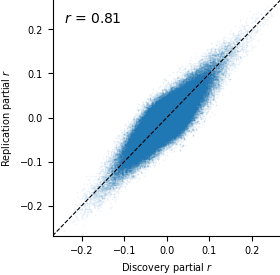

In [11]:
res_A=split_results["A"]["results_plot"].copy()
res_B=split_results["B"]["results_plot"].copy()

common_variables=sorted(set(res_A["variable"]) & set(res_B["variable"]))
print("QC-retained environmental items modeled in both halves:",len(common_variables))

A=(
    res_A.loc[
        res_A["variable"].isin(common_variables),
        ["variable","feature","partial_r","p_fdr"]
    ]
    .rename(columns={"partial_r":"partial_r_A","p_fdr":"p_fdr_A"})
)

B=(
    res_B.loc[
        res_B["variable"].isin(common_variables),
        ["variable","feature","partial_r","p_fdr"]
    ]
    .rename(columns={"partial_r":"partial_r_B","p_fdr":"p_fdr_B"})
)

AB=A.merge(B,on=["variable","feature"],how="inner",validate="one_to_one")
expected_pairs=len(common_variables)*len(wm_cols)
print("Aligned item × WM-feature pairs:",len(AB))
print("Expected aligned pairs:",expected_pairs)
if len(AB)!=expected_pairs:
    raise ValueError(
        "A/B concordance table does not contain the expected number of aligned item × feature pairs."
    )

global_r=stats.pearsonr(AB["partial_r_A"],AB["partial_r_B"]).statistic

AB["sig_A"]=AB["p_fdr_A"]<.05
AB["sig_B"]=AB["p_fdr_B"]<.05
AB["sig_both"]=AB["sig_A"] & AB["sig_B"]
AB["sig_union"]=AB["sig_A"] | AB["sig_B"]

n_sig_A=int(AB["sig_A"].sum())
n_sig_B=int(AB["sig_B"].sum())
n_sig_both=int(AB["sig_both"].sum())
n_sig_union=int(AB["sig_union"].sum())

jaccard=n_sig_both/n_sig_union if n_sig_union else np.nan
replication_A_to_B=100*n_sig_both/n_sig_A if n_sig_A else np.nan
replication_B_to_A=100*n_sig_both/n_sig_B if n_sig_B else np.nan
sign_agreement_global=(
    100*np.mean(
        np.sign(AB.loc[AB["sig_both"],"partial_r_A"])==
        np.sign(AB.loc[AB["sig_both"],"partial_r_B"])
    )
    if n_sig_both else np.nan
)

global_concordance=pd.DataFrame([{
    "n_items":len(common_variables),
    "n_wm_features":len(wm_cols),
    "n_item_feature_pairs":len(AB),
    "partial_r_map_correlation_A_B":global_r,
    "n_fdr_A":n_sig_A,
    "n_fdr_B":n_sig_B,
    "n_fdr_both":n_sig_both,
    "n_fdr_union":n_sig_union,
    "fdr_jaccard":jaccard,
    "fdr_replication_A_to_B_pct":replication_A_to_B,
    "fdr_replication_B_to_A_pct":replication_B_to_A,
    "sign_agreement_among_both_fdr_pct":sign_agreement_global
}])

print(f"\nGlobal discovery–replication partial-r concordance: r={global_r:.4f}")
display(global_concordance)

global_concordance.to_csv(CONCORDANCE_DIR/"global_split_half_concordance.csv",index=False)
AB.to_csv(CONCORDANCE_DIR/"aligned_item_feature_effects_A_B.csv",index=False)

item_concordance_rows=[]
for var,d in AB.groupby("variable",sort=False):
    r_ab=stats.pearsonr(d["partial_r_A"],d["partial_r_B"]).statistic
    sig_A=d["sig_A"]
    sig_B=d["sig_B"]
    both=sig_A & sig_B
    union=sig_A | sig_B
    n_A=int(sig_A.sum())
    n_B=int(sig_B.sum())
    n_both=int(both.sum())
    n_union=int(union.sum())
    sign_agreement=(
        100*np.mean(
            np.sign(d.loc[both,"partial_r_A"])==
            np.sign(d.loc[both,"partial_r_B"])
        )
        if n_both else np.nan
    )

    item_concordance_rows.append({
        "variable":var,
        "map_r_A_B":r_ab,
        "n_fdr_A":n_A,
        "n_fdr_B":n_B,
        "n_fdr_both":n_both,
        "n_fdr_union":n_union,
        "fdr_jaccard":n_both/n_union if n_union else np.nan,
        "fdr_replication_A_to_B_pct":100*n_both/n_A if n_A else np.nan,
        "fdr_replication_B_to_A_pct":100*n_both/n_B if n_B else np.nan,
        "sign_agreement_among_both_fdr_pct":sign_agreement
    })

item_concordance=pd.DataFrame(item_concordance_rows).merge(
    qc_map[["variable","construct_category","ecological_level"]],
    on="variable",how="left",validate="one_to_one"
)
item_concordance=item_concordance.sort_values("map_r_A_B",ascending=False).reset_index(drop=True)
item_concordance.to_csv(CONCORDANCE_DIR/"per_item_split_half_concordance.csv",index=False)

display(item_concordance.head(30))

# Concordance scatter: all aligned environmental-item × WM-feature effects.
from figure_formatting import setup_figure,save_figure

fig,ax=setup_figure(
    width_mm=85,
    height_mm=82,
    margins_mm=(17,10,14,8),
    nrows=1,
    ncols=1,
    axes_linewidth=.8,
    base_pt=7,
    label_pt=7,
    title_pt=7
)

ax.scatter(
    AB["partial_r_A"],
    AB["partial_r_B"],
    s=1.5,
    alpha=.08,
    linewidths=0,
    rasterized=True
)

lim=max(AB["partial_r_A"].abs().max(),AB["partial_r_B"].abs().max())*1.03
ax.plot([-lim,lim],[-lim,lim],color="black",lw=.8,ls="--")
ax.set_xlim(-lim,lim)
ax.set_ylim(-lim,lim)
ax.set_xlabel(r"Discovery partial $r$")
ax.set_ylabel(r"Replication partial $r$")
ax.text(.05,.95,rf"$r$ = {global_r:.2f}",transform=ax.transAxes,ha="left",va="top")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

save_figure(fig,CONCORDANCE_DIR/"split_half_partial_r_concordance.svg",autofit=False)
fig.savefig(CONCORDANCE_DIR/"split_half_partial_r_concordance.png",dpi=600)
plt.show()


## 8. Feature parsing for heatmaps

In [12]:
PREFIXES=["Association_","Cerebellum_","Commissure_","ProjectionBrainstem_","ProjectionBasalGanglia_"]

METRIC_ORDER=[
    "NODDI_ICVF","NODDI_ISOVF","NODDI_OD",
    "1st_quarter_volume_mm3","2nd_and_3rd_quarter_volume_mm3","4th_quarter_volume_mm3",
    "volume_of_end_branches_1","volume_of_end_branches_2","total_volume_mm3",
    "area_of_end_region_1_mm2","area_of_end_region_2_mm2","total_area_of_end_regions_mm2",
    "total_surface_area_mm2","radius_of_end_region_1_mm","radius_of_end_region_2_mm",
    "total_radius_of_end_regions_mm","irregularity","curl","elongation","mean_length_mm","span_mm"
]

def parse_feature(feature):
    parts=feature.split("_")
    if len(parts)<4 or parts[0]!="bundle":
        return None,None
    bundle=parts[1]+"_"+parts[2]
    metric="_".join(parts[3:])
    return bundle,metric

def clean_bundle_label(bundle):
    x=bundle
    for p in PREFIXES:
        if x.startswith(p):
            x=x[len(p):]
            break
    side=""
    if x.endswith("L"):
        x=x[:-1]; side=" (L)"
    elif x.endswith("R"):
        x=x[:-1]; side=" (R)"
    x=re.sub(r"(?<!^)(?=[A-Z])"," ",x).replace("_"," ")
    return x+side

def clean_metric_label(metric):
    lookup={
        "NODDI_ICVF":"NODDI ICVF","NODDI_ISOVF":"NODDI ISOVF","NODDI_OD":"NODDI OD",
        "1st_quarter_volume_mm3":"1st Quarter Volume","2nd_and_3rd_quarter_volume_mm3":"2nd + 3rd Quarter Volume",
        "4th_quarter_volume_mm3":"4th Quarter Volume","volume_of_end_branches_1":"Volume of End Branches 1",
        "volume_of_end_branches_2":"Volume of End Branches 2","total_volume_mm3":"Total Volume",
        "area_of_end_region_1_mm2":"Area of End Region 1","area_of_end_region_2_mm2":"Area of End Region 2",
        "total_area_of_end_regions_mm2":"Total Area of End Regions","total_surface_area_mm2":"Total Surface Area",
        "radius_of_end_region_1_mm":"Radius of End Region 1","radius_of_end_region_2_mm":"Radius of End Region 2",
        "total_radius_of_end_regions_mm":"Total Radius of End Regions","irregularity":"Irregularity","curl":"Curl",
        "elongation":"Elongation","mean_length_mm":"Mean Length","span_mm":"Span"
    }
    return lookup.get(metric,metric)

feature_meta=pd.DataFrame({"feature":wm_cols})
feature_meta[["bundle","metric"]]=feature_meta["feature"].apply(lambda x:pd.Series(parse_feature(x)))
feature_meta["bundle_label"]=feature_meta["bundle"].map(clean_bundle_label)
feature_meta["metric_label"]=feature_meta["metric"].map(clean_metric_label)

bundle_order=feature_meta["bundle"].drop_duplicates().tolist()
metric_order=[m for m in METRIC_ORDER if m in set(feature_meta["metric"])]
print("Bundles:",len(bundle_order),"Metrics:",len(metric_order))

Bundles: 62 Metrics: 18


## 10. Brain-wide ranking by mean absolute partial r: discovery and replication side by side


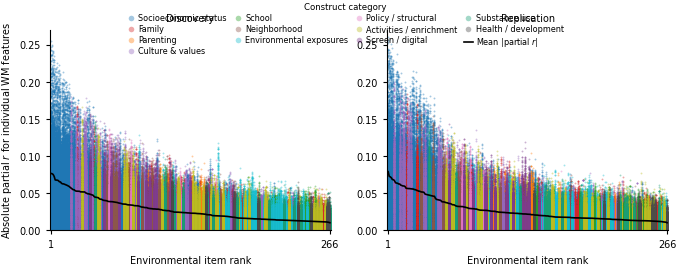


Top 25 by mean |partial r| — Discovery:


,variable,construct_category,ecological_level,n,missing_pct_in_imaging_sample,mean_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome
0,parent_ses,Socioeconomic & opportunity context,Family/household,4077,0.098015,0.076709,1047,0.989450
1,hshld_inc,Socioeconomic & opportunity context,Family/household,4077,0.098015,0.076295,1058,0.991298
2,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.075383,1056,-0.984265
3,reshist_addr1_coi_c5_coi_nat,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.072679,1031,0.982589
4,reshist_addr1_coi_se_single,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.067949,1004,-0.965156
5,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.067796,1000,-0.976326
6,reshist_addr1_coi_se_occ,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.067599,971,0.983590
7,reshist_addr1_coi_se_povrate,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.067013,1012,-0.971674
8,reshist_addr1_adi_perc,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.065478,957,-0.978000
9,reshist_addr1_coi_r_he_nat,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,0.065231,985,0.982501



Top 25 by mean |partial r| — Replication:


,variable,construct_category,ecological_level,n,missing_pct_in_imaging_sample,mean_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome
0,hshld_inc,Socioeconomic & opportunity context,Family/household,4093,0.146377,0.079079,1039,0.989596
1,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.072818,967,-0.984364
2,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.072134,1001,-0.970874
3,parent_ses,Socioeconomic & opportunity context,Family/household,4093,0.146377,0.070909,952,0.989835
4,reshist_addr1_coi_c5_coi_nat,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.068464,933,0.982862
5,reshist_addr1_adi_sp,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.068278,971,-0.967735
6,mex_american6_p,Culture & values,Family/household,4093,0.146377,0.067025,1026,-0.928675
7,reshist_addr1_coi_r_he_nat,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.064171,918,0.977855
8,reshist_addr1_adi_perc,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.063736,902,-0.982365
9,reshist_addr1_coi_se_single,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,0.063429,930,-0.969550


In [13]:
from figure_formatting import setup_figure,save_figure
import logging
import matplotlib as mpl

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
mpl.rcParams["font.family"]="sans-serif"
mpl.rcParams["font.sans-serif"]=["DejaVu Sans","Arial","Liberation Sans"]

W_MM=180
H_MM=72

legend_labels={
    "Socioeconomic & opportunity context":"Socioeconomic status",
    "Family environment":"Family",
    "Parenting":"Parenting",
    "Culture & values":"Culture & values",
    "School environment":"School",
    "Neighborhood & built environment":"Neighborhood",
    "Physical environment":"Environmental exposures",
    "Policy & structural context":"Policy / structural",
    "Activities & enrichment":"Activities / enrichment",
    "Screen & digital environment":"Screen / digital",
    "Substance-use environment":"Substance use",
    "Health / developmental history":"Health / development"
}

max_abs_r=max(
    split_results[split]["results_plot"]["partial_r"].abs().max()
    for split in ["A","B"]
)

fig,axes=setup_figure(
    width_mm=W_MM,
    height_mm=H_MM,
    margins_mm=(15,8,13,8),
    nrows=1,
    ncols=2,
    axes_linewidth=.8,
    base_pt=7,
    label_pt=7,
    title_pt=7
)
axes=np.atleast_1d(axes).ravel()

legend_handles=None
legend_text=None

for ax,split in zip(axes,["A","B"]):
    summary_plot_split=split_results[split]["summary_plot"]
    results_plot_split=split_results[split]["results_plot"]

    rank_mean=(
        summary_plot_split
        .sort_values("mean_abs_partial_r",ascending=False)["variable"]
        .tolist()
    )
    rank_lookup={v:i for i,v in enumerate(rank_mean)}

    plot_df=(
        results_plot_split[["variable","partial_r"]]
        .merge(
            qc_final[["variable","construct_category"]],
            on="variable",how="inner",validate="many_to_one"
        )
    )
    plot_df["x"]=plot_df["variable"].map(rank_lookup)
    plot_df["abs_partial_r"]=plot_df["partial_r"].abs()

    mean_line=(
        summary_plot_split
        .set_index("variable")
        .loc[rank_mean,"mean_abs_partial_r"]
        .to_numpy()
    )

    for category in construct_order:
        d=plot_df.loc[plot_df["construct_category"]==category]
        if len(d):
            ax.scatter(
                d["x"],d["abs_partial_r"],
                s=1.8,alpha=.40,rasterized=True,
                color=construct_palette[category],linewidths=0,
                label=legend_labels.get(category,category)
            )

    ax.plot(
        np.arange(len(rank_mean)),mean_line,
        lw=1.2,color="black",label=r"Mean |partial $r$|",zorder=10
    )

    ax.set_xlim(-1,len(rank_mean))
    ax.set_ylim(0,max_abs_r*1.04)
    ax.set_xlabel("Environmental item rank")
    ax.set_title(SPLITS[split]["label"])

    if len(rank_mean)>1:
        ax.set_xticks([0,len(rank_mean)-1])
        ax.set_xticklabels(["1",str(len(rank_mean))])
    else:
        ax.set_xticks([0])
        ax.set_xticklabels(["1"])

    ax.tick_params(axis="both",width=.8,length=3,direction="out")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if legend_handles is None:
        legend_handles,legend_text=ax.get_legend_handles_labels()

axes[0].set_ylabel(r"Absolute partial $r$ for individual WM features")
axes[1].set_ylabel("")

# One shared legend for both panels.
fig.legend(
    legend_handles,legend_text,
    title="Construct category",
    loc="upper center",bbox_to_anchor=(.5,1.01),
    ncol=4,frameon=False,
    fontsize=5.8,title_fontsize=6.2,
    markerscale=3,handlelength=1.1,handletextpad=.35,
    columnspacing=.8,labelspacing=.25
)

save_figure(fig,OUT_DIR/"brainwide_rank_mean_abs_partial_r_A_B.svg",autofit=False)
fig.savefig(OUT_DIR/"brainwide_rank_mean_abs_partial_r_A_B.png",dpi=600)
plt.show()

for split in ["A","B"]:
    print(f"\nTop 25 by mean |partial r| — {SPLITS[split]['label']}:")
    display(
        split_results[split]["summary_plot"]
        .sort_values("mean_abs_partial_r",ascending=False)
        .head(25)[[
            "variable","construct_category","ecological_level","n",
            "missing_pct_in_imaging_sample","mean_abs_partial_r",
            "n_fdr_sig","map_r_vs_general_exposome"
        ]]
    )


## 11. Brain-wide ranking by number of FDR-significant WM features: discovery and replication side by side


In [14]:
for split in ["A","B"]:
    summary_plot_split=split_results[split]["summary_plot"]

    top5_mean=(
        summary_plot_split
        .sort_values("mean_abs_partial_r",ascending=False)
        .head(5)["variable"]
        .tolist()
    )

    rank_fdr=(
        summary_plot_split
        .sort_values(["n_fdr_sig","mean_abs_partial_r"],ascending=[False,False])
        .reset_index(drop=True)
    )
    top5_fdr=rank_fdr.head(5)["variable"].tolist()
    top5_overlap=set(top5_mean)&set(top5_fdr)

    print(f"\n{SPLITS[split]['label']} split {split}")
    print("Top 5 by mean |partial r|:",top5_mean)
    print("Top 5 by FDR-significant features:",top5_fdr)
    print(f"Top-5 overlap: {len(top5_overlap)}/5")
    print("Shared variables:",sorted(top5_overlap))



Discovery split A
Top 5 by mean |partial r|: ['parent_ses', 'hshld_inc', 'addr_poverty', 'reshist_addr1_coi_c5_coi_nat', 'reshist_addr1_coi_se_single']
Top 5 by FDR-significant features: ['hshld_inc', 'addr_poverty', 'parent_ses', 'reshist_addr1_coi_c5_coi_nat', 'reshist_addr1_coi_se_povrate']
Top-5 overlap: 4/5
Shared variables: ['addr_poverty', 'hshld_inc', 'parent_ses', 'reshist_addr1_coi_c5_coi_nat']

Replication split B
Top 5 by mean |partial r|: ['hshld_inc', 'addr_poverty', 'reshist_addr1_coi_se_public', 'parent_ses', 'reshist_addr1_coi_c5_coi_nat']
Top 5 by FDR-significant features: ['hshld_inc', 'mex_american6_p', 'reshist_addr1_coi_se_public', 'mexAm_Religiosity', 'reshist_addr1_adi_sp']
Top-5 overlap: 2/5
Shared variables: ['hshld_inc', 'reshist_addr1_coi_se_public']


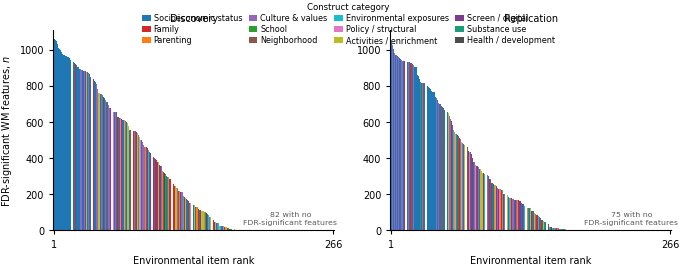


Top 25 by number of FDR-significant features — Discovery:


,variable,construct_category,ecological_level,n,missing_pct_in_imaging_sample,n_fdr_sig,mean_abs_partial_r,fdr_overlap_with_general_n,fdr_overlap_pct_of_item,map_r_vs_general_exposome
0,hshld_inc,Socioeconomic & opportunity context,Family/household,4077,0.098015,1058,0.076295,1043,98.582231,0.991298
1,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,1056,0.075383,1034,97.916667,-0.984265
2,parent_ses,Socioeconomic & opportunity context,Family/household,4077,0.098015,1047,0.076709,1033,98.662846,0.989450
3,reshist_addr1_coi_c5_coi_nat,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,1031,0.072679,1010,97.963143,0.982589
4,reshist_addr1_coi_se_povrate,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,1012,0.067013,1001,98.913043,-0.971674
5,reshist_addr1_coi_se_single,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,1004,0.067949,981,97.709163,-0.965156
6,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,1000,0.067796,982,98.200000,-0.976326
7,reshist_addr1_coi_r_he_nat,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,985,0.065231,974,98.883249,0.982501
8,reshist_addr1_adi_unemp,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,975,0.060869,954,97.846154,-0.968195
9,reshist_addr1_coi_se_occ,Socioeconomic & opportunity context,Neighborhood/community,3750,8.110757,971,0.067599,964,99.279094,0.983590



Top 25 by number of FDR-significant features — Replication:


,variable,construct_category,ecological_level,n,missing_pct_in_imaging_sample,n_fdr_sig,mean_abs_partial_r,fdr_overlap_with_general_n,fdr_overlap_pct_of_item,map_r_vs_general_exposome
0,hshld_inc,Socioeconomic & opportunity context,Family/household,4093,0.146377,1039,0.079079,979,94.225217,0.989596
1,mex_american6_p,Culture & values,Family/household,4093,0.146377,1026,0.067025,931,90.740741,-0.928675
2,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,1001,0.072134,944,94.305694,-0.970874
3,mexAm_Religiosity,Culture & values,Family/household,4093,0.146377,983,0.062434,928,94.404883,-0.952888
4,reshist_addr1_adi_sp,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,971,0.068278,930,95.777549,-0.967735
5,mex_american11_p,Culture & values,Family/household,4093,0.146377,971,0.059861,920,94.747683,-0.953185
6,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,967,0.072818,951,98.345398,-0.984364
7,mex_american25_p,Culture & values,Family/household,4093,0.146377,962,0.059812,914,95.010395,-0.949145
8,parent_ses,Socioeconomic & opportunity context,Family/household,4093,0.146377,952,0.070909,931,97.794118,0.989835
9,reshist_addr1_adi_unemp,Socioeconomic & opportunity context,Neighborhood/community,3711,9.465723,950,0.060985,908,95.578947,-0.965916


In [15]:
from figure_formatting import setup_figure,save_figure

max_fdr=max(
    split_results[split]["summary_plot"]["n_fdr_sig"].max()
    for split in ["A","B"]
)

fig,axes=setup_figure(
    width_mm=180,
    height_mm=72,
    margins_mm=(15,8,13,8),
    nrows=1,
    ncols=2,
    axes_linewidth=.8,
    base_pt=7,
    label_pt=7,
    title_pt=7
)
axes=np.atleast_1d(axes).ravel()

for ax,split in zip(axes,["A","B"]):
    rank_fdr=(
        split_results[split]["summary_plot"]
        .sort_values(["n_fdr_sig","mean_abs_partial_r"],ascending=[False,False])
        .reset_index(drop=True)
    )

    missing_bar_categories=sorted(set(rank_fdr["construct_category"])-set(construct_palette))
    assert not missing_bar_categories,f"Missing construct colors for: {missing_bar_categories}"

    bar_colors=rank_fdr["construct_category"].map(construct_palette).tolist()
    n_items=len(rank_fdr)
    n_zero=int((rank_fdr["n_fdr_sig"]==0).sum())
    n_nonzero=n_items-n_zero

    x=np.arange(n_items)
    ax.bar(x,rank_fdr["n_fdr_sig"].to_numpy(),color=bar_colors,width=.9,linewidth=0)

    ax.set_xlim(-1,n_items)
    ax.set_ylim(0,max_fdr*1.05)
    ax.set_xlabel("Environmental item rank")
    ax.set_title(SPLITS[split]["label"])
    ax.set_xticks([0,n_items-1] if n_items>1 else [0])
    ax.set_xticklabels(["1",str(n_items)] if n_items>1 else ["1"])
    ax.tick_params(axis="both",width=.8,length=3,direction="out")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if n_zero>0:
        ax.text(
            n_nonzero+(n_zero-1)/2,.025*max_fdr,
            f"{n_zero} with no\nFDR-significant features",
            ha="center",va="bottom",fontsize=5.6,color=".35"
        )

axes[0].set_ylabel(r"FDR-significant WM features, $n$")
axes[1].set_ylabel("")

# Shared construct legend.
legend_handles=[Patch(facecolor=construct_palette[c],label=c) for c in construct_order]
fig.legend(
    legend_handles,
    [legend_labels.get(c,c) for c in construct_order],
    title="Construct category",
    loc="upper center",bbox_to_anchor=(.5,1.01),
    ncol=4,frameon=False,
    fontsize=5.8,title_fontsize=6.2,
    handlelength=1.1,handletextpad=.35,
    columnspacing=.8,labelspacing=.25
)

save_figure(fig,OUT_DIR/"brainwide_rank_n_fdr_significant_A_B.svg",autofit=False)
fig.savefig(OUT_DIR/"brainwide_rank_n_fdr_significant_A_B.png",dpi=600)
plt.show()

for split in ["A","B"]:
    rank_fdr=(
        split_results[split]["summary_plot"]
        .sort_values(["n_fdr_sig","mean_abs_partial_r"],ascending=[False,False])
        .reset_index(drop=True)
    )
    print(f"\nTop 25 by number of FDR-significant features — {SPLITS[split]['label']}:")
    display(rank_fdr.head(25)[[
        "variable","construct_category","ecological_level","n",
        "missing_pct_in_imaging_sample","n_fdr_sig","mean_abs_partial_r",
        "fdr_overlap_with_general_n","fdr_overlap_pct_of_item",
        "map_r_vs_general_exposome"
    ]])


## 12. General Exposome comparison, separately by split


In [16]:
comparison_cols=[
    "variable","construct_category","ecological_level","n","missing_pct_in_imaging_sample",
    "mean_abs_partial_r","n_fdr_sig","map_r_vs_general_exposome","abs_map_r_vs_general_exposome",
    "fdr_overlap_with_general_n","fdr_overlap_pct_of_item","rank_mean_abs_r_filtered","rank_n_fdr_filtered"
]

for split in ["A","B"]:
    summary_plot=split_results[split]["summary_plot"]
    general_results=split_results[split]["general_results"]

    comparison=(
        summary_plot[comparison_cols]
        .sort_values("abs_map_r_vs_general_exposome",ascending=False)
    )
    comparison.to_csv(
        SPLIT_DIRS[split]/"item_vs_general_exposome_comparison.csv",
        index=False
    )

    general_mean_abs=general_results["partial_r"].abs().mean()
    general_median_abs=general_results["partial_r"].abs().median()
    general_max_abs=general_results["partial_r"].abs().max()
    general_n_fdr=int((general_results["p_fdr"]<.05).sum())

    print("\n"+"="*70)
    print(f"{SPLITS[split]['label']} — General Exposome reference")
    print("="*70)
    print(f"N = {int(general_results['n'].iloc[0])}")
    print(f"mean |partial r| = {general_mean_abs:.4f}")
    print(f"median |partial r| = {general_median_abs:.4f}")
    print(f"max |partial r| = {general_max_abs:.4f}")
    print(f"FDR-significant WM features = {general_n_fdr}/{len(general_results)}")

    top_compare=(
        summary_plot
        .sort_values(["n_fdr_sig","mean_abs_partial_r"],ascending=[False,False])
        .head(10)
        .copy()
    )
    top_compare["mean_abs_r_pct_of_general"]=100*top_compare["mean_abs_partial_r"]/general_mean_abs
    top_compare["n_fdr_pct_of_general"]=100*top_compare["n_fdr_sig"]/general_n_fdr if general_n_fdr else np.nan
    top_compare["fdr_count_difference_vs_general"]=top_compare["n_fdr_sig"]-general_n_fdr

    general_row=pd.DataFrame([{
        "variable":"General Exposome","construct_category":"General factor","ecological_level":"Multilevel",
        "n":int(general_results["n"].iloc[0]),"mean_abs_partial_r":general_mean_abs,
        "n_fdr_sig":general_n_fdr,"map_r_vs_general_exposome":1.0,
        "abs_map_r_vs_general_exposome":1.0,"mean_abs_r_pct_of_general":100.0,
        "n_fdr_pct_of_general":100.0,"fdr_count_difference_vs_general":0
    }])

    top_vs_general=pd.concat([general_row,top_compare[[
        "variable","construct_category","ecological_level","n","mean_abs_partial_r","n_fdr_sig",
        "map_r_vs_general_exposome","abs_map_r_vs_general_exposome","mean_abs_r_pct_of_general",
        "n_fdr_pct_of_general","fdr_count_difference_vs_general"
    ]]],ignore_index=True)

    top_vs_general.to_csv(
        SPLIT_DIRS[split]/"top_items_vs_general_exposome.csv",
        index=False
    )
    display(top_vs_general)



Discovery — General Exposome reference
N = 4081
mean |partial r| = 0.0942
median |partial r| = 0.0891
max |partial r| = 0.3147
FDR-significant WM features = 1119/1302


,variable,construct_category,ecological_level,n,mean_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome,abs_map_r_vs_general_exposome,mean_abs_r_pct_of_general,n_fdr_pct_of_general,fdr_count_difference_vs_general
0,General Exposome,General factor,Multilevel,4081,0.094196,1119,1.000000,1.000000,100.000000,100.000000,0
1,hshld_inc,Socioeconomic & opportunity context,Family/household,4077,0.076295,1058,0.991298,0.991298,80.996170,94.548704,-61
2,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,3750,0.075383,1056,-0.984265,0.984265,80.027454,94.369973,-63
3,parent_ses,Socioeconomic & opportunity context,Family/household,4077,0.076709,1047,0.989450,0.989450,81.434823,93.565684,-72
4,reshist_addr1_coi_c5_coi_nat,Socioeconomic & opportunity context,Neighborhood/community,3750,0.072679,1031,0.982589,0.982589,77.156749,92.135836,-88
5,reshist_addr1_coi_se_povrate,Socioeconomic & opportunity context,Neighborhood/community,3750,0.067013,1012,-0.971674,0.971674,71.141409,90.437891,-107
6,reshist_addr1_coi_se_single,Socioeconomic & opportunity context,Neighborhood/community,3750,0.067949,1004,-0.965156,0.965156,72.135428,89.722967,-115
7,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,3750,0.067796,1000,-0.976326,0.976326,71.973163,89.365505,-119
8,reshist_addr1_coi_r_he_nat,Socioeconomic & opportunity context,Neighborhood/community,3750,0.065231,985,0.982501,0.982501,69.249566,88.025022,-134
9,reshist_addr1_adi_unemp,Socioeconomic & opportunity context,Neighborhood/community,3750,0.060869,975,-0.968195,0.968195,64.619665,87.131367,-144



Replication — General Exposome reference
N = 4099
mean |partial r| = 0.0867
median |partial r| = 0.0822
max |partial r| = 0.3023
FDR-significant WM features = 1022/1302


,variable,construct_category,ecological_level,n,mean_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome,abs_map_r_vs_general_exposome,mean_abs_r_pct_of_general,n_fdr_pct_of_general,fdr_count_difference_vs_general
0,General Exposome,General factor,Multilevel,4099,0.086697,1022,1.000000,1.000000,100.000000,100.000000,0
1,hshld_inc,Socioeconomic & opportunity context,Family/household,4093,0.079079,1039,0.989596,0.989596,91.212824,101.663405,17
2,mex_american6_p,Culture & values,Family/household,4093,0.067025,1026,-0.928675,0.928675,77.309634,100.391389,4
3,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,3711,0.072134,1001,-0.970874,0.970874,83.201926,97.945205,-21
4,mexAm_Religiosity,Culture & values,Family/household,4093,0.062434,983,-0.952888,0.952888,72.013933,96.183953,-39
5,reshist_addr1_adi_sp,Socioeconomic & opportunity context,Neighborhood/community,3711,0.068278,971,-0.967735,0.967735,78.754950,95.009785,-51
6,mex_american11_p,Culture & values,Family/household,4093,0.059861,971,-0.953185,0.953185,69.046435,95.009785,-51
7,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,3711,0.072818,967,-0.984364,0.984364,83.991560,94.618395,-55
8,mex_american25_p,Culture & values,Family/household,4093,0.059812,962,-0.949145,0.949145,68.989004,94.129159,-60
9,parent_ses,Socioeconomic & opportunity context,Family/household,4093,0.070909,952,0.989835,0.989835,81.788642,93.150685,-70


## 12b. Top-item General Exposome map similarity, separately by split

To avoid generating hundreds of figures, this section summarizes map similarity only for `TOP_N_HEATMAPS` top-ranked items in each split. Selection is performed independently within discovery and replication using the QC-filtered results.


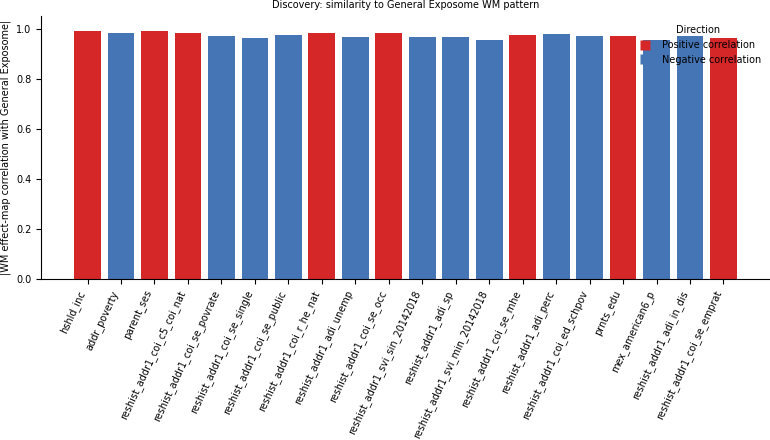


Discovery top map correlations:


,variable,construct_category,ecological_level,mean_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome,map_r_abs,map_direction
1,hshld_inc,Socioeconomic & opportunity context,Family/household,0.076295,1058,0.991298,0.991298,Positive
2,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,0.075383,1056,-0.984265,0.984265,Negative
0,parent_ses,Socioeconomic & opportunity context,Family/household,0.076709,1047,0.989450,0.989450,Positive
3,reshist_addr1_coi_c5_coi_nat,Socioeconomic & opportunity context,Neighborhood/community,0.072679,1031,0.982589,0.982589,Positive
7,reshist_addr1_coi_se_povrate,Socioeconomic & opportunity context,Neighborhood/community,0.067013,1012,-0.971674,0.971674,Negative
4,reshist_addr1_coi_se_single,Socioeconomic & opportunity context,Neighborhood/community,0.067949,1004,-0.965156,0.965156,Negative
5,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,0.067796,1000,-0.976326,0.976326,Negative
9,reshist_addr1_coi_r_he_nat,Socioeconomic & opportunity context,Neighborhood/community,0.065231,985,0.982501,0.982501,Positive
15,reshist_addr1_adi_unemp,Socioeconomic & opportunity context,Neighborhood/community,0.060869,975,-0.968195,0.968195,Negative
6,reshist_addr1_coi_se_occ,Socioeconomic & opportunity context,Neighborhood/community,0.067599,971,0.983590,0.983590,Positive


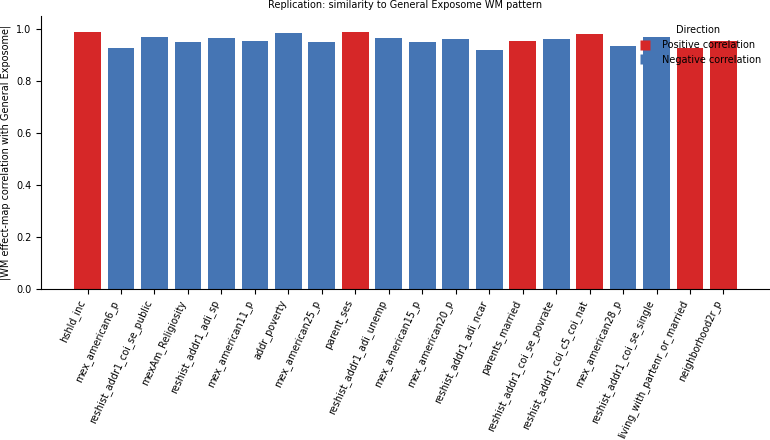


Replication top map correlations:


,variable,construct_category,ecological_level,mean_abs_partial_r,n_fdr_sig,map_r_vs_general_exposome,map_r_abs,map_direction
0,hshld_inc,Socioeconomic & opportunity context,Family/household,0.079079,1039,0.989596,0.989596,Positive
6,mex_american6_p,Culture & values,Family/household,0.067025,1026,-0.928675,0.928675,Negative
2,reshist_addr1_coi_se_public,Socioeconomic & opportunity context,Neighborhood/community,0.072134,1001,-0.970874,0.970874,Negative
11,mexAm_Religiosity,Culture & values,Family/household,0.062434,983,-0.952888,0.952888,Negative
5,reshist_addr1_adi_sp,Socioeconomic & opportunity context,Neighborhood/community,0.068278,971,-0.967735,0.967735,Negative
14,mex_american11_p,Culture & values,Family/household,0.059861,971,-0.953185,0.953185,Negative
1,addr_poverty,Socioeconomic & opportunity context,Neighborhood/community,0.072818,967,-0.984364,0.984364,Negative
15,mex_american25_p,Culture & values,Family/household,0.059812,962,-0.949145,0.949145,Negative
3,parent_ses,Socioeconomic & opportunity context,Family/household,0.070909,952,0.989835,0.989835,Positive
12,reshist_addr1_adi_unemp,Socioeconomic & opportunity context,Neighborhood/community,0.060985,950,-0.965916,0.965916,Negative


In [17]:
direction_colors={"Positive":"#d62728","Negative":"#4575b4"}

for split in ["A","B"]:
    summary_plot=split_results[split]["summary_plot"]

    corr_rank=(
        summary_plot.sort_values(
            [TOP_HEATMAP_RANK_BY,"mean_abs_partial_r"],
            ascending=[False,False]
        )
        if TOP_HEATMAP_RANK_BY=="n_fdr_sig"
        else summary_plot.sort_values(TOP_HEATMAP_RANK_BY,ascending=False)
    )

    top_corr=corr_rank.head(TOP_N_HEATMAPS).copy()
    top_corr["map_r_abs"]=top_corr["map_r_vs_general_exposome"].abs()
    top_corr["map_direction"]=np.where(
        top_corr["map_r_vs_general_exposome"]>=0,"Positive","Negative"
    )

    bar_colors=top_corr["map_direction"].map(direction_colors)
    assert bar_colors.notna().all(),"Missing direction color for map-correlation plot."

    fig,ax=plt.subplots(figsize=(8,4.7))
    x=np.arange(len(top_corr))
    ax.bar(x,top_corr["map_r_abs"],color=bar_colors.tolist())

    ax.set_ylim(0,1.05)
    ax.set_ylabel("|WM effect-map correlation with General Exposome|")
    ax.set_xlabel("")
    ax.set_title(f"{SPLITS[split]['label']}: similarity to General Exposome WM pattern")
    ax.set_xticks(x)
    ax.set_xticklabels(top_corr["variable"],rotation=65,ha="right",fontsize=7)

    direction_handles=[
        plt.Line2D([0],[0],marker="s",linestyle="",markersize=7,
                   markerfacecolor=direction_colors["Positive"],markeredgecolor="none",
                   label="Positive correlation"),
        plt.Line2D([0],[0],marker="s",linestyle="",markersize=7,
                   markerfacecolor=direction_colors["Negative"],markeredgecolor="none",
                   label="Negative correlation")
    ]
    ax.legend(handles=direction_handles,title="Direction",loc="upper right",frameon=False,fontsize=7,title_fontsize=7)
    sns.despine()
    plt.tight_layout()

    fig.savefig(
        SPLIT_DIRS[split]/"top_items_map_correlation_with_general_exposome.png",
        dpi=400,bbox_inches="tight"
    )
    fig.savefig(
        SPLIT_DIRS[split]/"top_items_map_correlation_with_general_exposome.svg",
        bbox_inches="tight"
    )
    plt.show()

    print(f"\n{SPLITS[split]['label']} top map correlations:")
    display(top_corr[[
        "variable","construct_category","ecological_level","mean_abs_partial_r","n_fdr_sig",
        "map_r_vs_general_exposome","map_r_abs","map_direction"
    ]])


## 14. Quick output inventory


In [18]:
print("Main paired outputs:")
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file():
        print(" -",p.name)

for split in ["A","B"]:
    print(f"\nSplit {split} ({SPLITS[split]['label']}) outputs:")
    for p in sorted(SPLIT_DIRS[split].iterdir()):
        if p.is_file():
            print(" -",p.name)
    print(f" Item heatmaps: {len(list(SPLIT_HEATMAP_DIRS[split].glob('*.png')))}")

print("\nConcordance outputs:")
for p in sorted(CONCORDANCE_DIR.iterdir()):
    if p.is_file():
        print(" -",p.name)


Main paired outputs:
 - brainwide_rank_mean_abs_partial_r_A_B.png
 - brainwide_rank_mean_abs_partial_r_A_B.svg
 - brainwide_rank_n_fdr_significant_A_B.png
 - brainwide_rank_n_fdr_significant_A_B.svg
 - item_99999_replacements.csv
 - item_missingness_and_type_after_99999_cleanup.csv

Split A (Discovery) outputs:
 - General_SES_mass_univariate_reference.csv
 - all_item_mass_univariate_results.csv
 - item_mass_univariate_summary.csv
 - item_mass_univariate_summary_qc_filtered.csv
 - item_missingness_in_imaging_sample.csv
 - item_vs_general_exposome_comparison.csv
 - skipped_items.csv
 - top_items_map_correlation_with_general_exposome.png
 - top_items_map_correlation_with_general_exposome.svg
 - top_items_vs_general_exposome.csv
 Item heatmaps: 0

Split B (Replication) outputs:
 - General_SES_mass_univariate_reference.csv
 - all_item_mass_univariate_results.csv
 - item_mass_univariate_summary.csv
 - item_mass_univariate_summary_qc_filtered.csv
 - item_missingness_in_imaging_sample.csv
 - i

## 15. Permutation testing, separately by split


In [19]:
def between_group_ss(y,g):
    grand=np.mean(y)
    return sum(len(y[g==cat])*(np.mean(y[g==cat])-grand)**2 for cat in np.unique(g))

omnibus_rows=[]
for split in ["A","B"]:
    test_df=(
        split_results[split]["summary_plot"]
        .dropna(subset=["construct_category","mean_abs_partial_r"])
        .copy()
    )
    y=test_df["mean_abs_partial_r"].to_numpy()
    g=test_df["construct_category"].to_numpy()

    rng=np.random.default_rng(42)
    obs_ss=between_group_ss(y,g)
    perm_ss=np.array([between_group_ss(rng.permutation(y),g) for _ in range(10000)])
    p_omnibus=(np.sum(perm_ss>=obs_ss)+1)/(len(perm_ss)+1)

    omnibus_rows.append({
        "split":split,
        "sample":SPLITS[split]["label"],
        "n_items":len(test_df),
        "observed_between_group_ss":obs_ss,
        "p_perm":p_omnibus
    })
    print(f"{SPLITS[split]['label']} permutation omnibus p={p_omnibus:.4g}")

omnibus_tests=pd.DataFrame(omnibus_rows)
omnibus_tests.to_csv(OUT_DIR/"construct_permutation_omnibus_A_B.csv",index=False)
display(omnibus_tests)


Discovery permutation omnibus p=9.999e-05
Replication permutation omnibus p=9.999e-05


,split,sample,n_items,observed_between_group_ss,p_perm
0,A,Discovery,266,0.027534,0.0001
1,B,Replication,266,0.024933,0.0001


In [20]:
def permutation_mean_diff(a,b,n_perm=10000,seed=42):
    a=np.asarray(a,dtype=float)
    b=np.asarray(b,dtype=float)
    rng=np.random.default_rng(seed)
    pooled=np.concatenate([a,b])
    n_a=len(a)
    obs=a.mean()-b.mean()
    null=np.empty(n_perm)
    for i in range(n_perm):
        p=rng.permutation(pooled)
        null[i]=p[:n_a].mean()-p[n_a:].mean()
    p=(np.sum(np.abs(null)>=abs(obs))+1)/(n_perm+1)
    return obs,p

ses="Socioeconomic & opportunity context"
ses_tests_by_split={}

for split in ["A","B"]:
    test_df=(
        split_results[split]["summary_plot"]
        .dropna(subset=["construct_category","mean_abs_partial_r"])
        .copy()
    )
    ses_vals=test_df.loc[
        test_df["construct_category"]==ses,
        "mean_abs_partial_r"
    ].to_numpy()

    rows=[]
    for cat in sorted(test_df["construct_category"].unique()):
        if cat==ses:
            continue
        other=test_df.loc[
            test_df["construct_category"]==cat,
            "mean_abs_partial_r"
        ].to_numpy()
        diff,p=permutation_mean_diff(ses_vals,other)
        rows.append({
            "split":split,
            "sample":SPLITS[split]["label"],
            "comparison":f"{ses} vs {cat}",
            "n_ses":len(ses_vals),
            "n_other":len(other),
            "mean_ses":ses_vals.mean(),
            "mean_other":other.mean(),
            "difference":diff,
            "p_perm":p
        })

    ses_tests=pd.DataFrame(rows)
    if len(ses_tests):
        ses_tests["p_fdr"]=multipletests(ses_tests["p_perm"],method="fdr_bh")[1]
        ses_tests=ses_tests.sort_values("difference",ascending=False)

    ses_tests_by_split[split]=ses_tests
    ses_tests.to_csv(
        SPLIT_DIRS[split]/"socioeconomic_construct_pairwise_permutation_tests.csv",
        index=False
    )

    print(f"\n{SPLITS[split]['label']} pairwise construct tests:")
    display(ses_tests)



Discovery pairwise construct tests:


,split,sample,comparison,n_ses,n_other,mean_ses,mean_other,difference,p_perm,p_fdr
8,A,Discovery,Socioeconomic & opportunity context vs School ...,59,16,0.044435,0.014463,0.029972,0.000100,0.000220
3,A,Discovery,Socioeconomic & opportunity context vs Health ...,59,8,0.044435,0.016038,0.028396,0.000200,0.000367
6,A,Discovery,Socioeconomic & opportunity context vs Physica...,59,30,0.044435,0.016512,0.027923,0.000100,0.000220
10,A,Discovery,Socioeconomic & opportunity context vs Substan...,59,13,0.044435,0.019566,0.024869,0.000100,0.000220
5,A,Discovery,Socioeconomic & opportunity context vs Parenting,59,10,0.044435,0.022338,0.022097,0.000300,0.000471
0,A,Discovery,Socioeconomic & opportunity context vs Activit...,59,35,0.044435,0.022444,0.021991,0.000100,0.000220
2,A,Discovery,Socioeconomic & opportunity context vs Family ...,59,25,0.044435,0.023259,0.021176,0.000100,0.000220
4,A,Discovery,Socioeconomic & opportunity context vs Neighbo...,59,14,0.044435,0.029082,0.015353,0.004700,0.005744
9,A,Discovery,Socioeconomic & opportunity context vs Screen ...,59,15,0.044435,0.030828,0.013607,0.008799,0.009679
7,A,Discovery,Socioeconomic & opportunity context vs Policy ...,59,5,0.044435,0.031163,0.013272,0.136086,0.136086



Replication pairwise construct tests:


,split,sample,comparison,n_ses,n_other,mean_ses,mean_other,difference,p_perm,p_fdr
3,B,Replication,Socioeconomic & opportunity context vs Health ...,59,8,0.042552,0.014109,0.028442,0.000200,0.000314
8,B,Replication,Socioeconomic & opportunity context vs School ...,59,16,0.042552,0.015026,0.027525,0.000100,0.000183
6,B,Replication,Socioeconomic & opportunity context vs Physica...,59,30,0.042552,0.018313,0.024239,0.000100,0.000183
0,B,Replication,Socioeconomic & opportunity context vs Activit...,59,35,0.042552,0.020041,0.022510,0.000100,0.000183
10,B,Replication,Socioeconomic & opportunity context vs Substan...,59,13,0.042552,0.020300,0.022252,0.000100,0.000183
5,B,Replication,Socioeconomic & opportunity context vs Parenting,59,10,0.042552,0.020329,0.022222,0.000100,0.000183
2,B,Replication,Socioeconomic & opportunity context vs Family ...,59,25,0.042552,0.021508,0.021044,0.000100,0.000183
9,B,Replication,Socioeconomic & opportunity context vs Screen ...,59,15,0.042552,0.025451,0.017101,0.001000,0.001375
7,B,Replication,Socioeconomic & opportunity context vs Policy ...,59,5,0.042552,0.028740,0.013812,0.107089,0.107089
4,B,Replication,Socioeconomic & opportunity context vs Neighbo...,59,14,0.042552,0.030264,0.012287,0.020498,0.022548


In [21]:
# Final downstream QC checks for both splits.
for split in ["A","B"]:
    summary=split_results[split]["summary"]
    summary_plot=split_results[split]["summary_plot"]

    print("\n"+"="*70)
    print(f"{SPLITS[split]['label']} split {split}")
    print("="*70)
    print(f"Retained environmental items: {len(summary_plot)}")
    print(f"Excluded as Needs clarification: {len(summary)-len(summary_plot)}")

    assert summary_plot["construct_category"].notna().all()
    assert summary_plot["ecological_level"].notna().all()
    assert summary_plot["variable"].is_unique
    assert set(summary_plot["construct_category"]).issubset(set(construct_palette))
    assert set(summary_plot["ecological_level"]).issubset(set(ecological_palette))

    print("\nFinal construct counts:")
    display(
        summary_plot["construct_category"]
        .value_counts()
        .reindex(construct_order)
        .rename("n")
        .to_frame()
    )

print("\nConcordance QC:")
assert AB[["partial_r_A","partial_r_B"]].notna().all().all()
assert item_concordance["variable"].is_unique
print("Aligned item × feature pairs:",len(AB))
print("Common modeled items:",len(common_variables))
print("Global map correlation:",global_r)



Discovery split A
Retained environmental items: 266
Excluded as Needs clarification: 0

Final construct counts:


,n
construct_category,
Socioeconomic & opportunity context,59
Family environment,25
Parenting,10
Culture & values,36
School environment,16
Neighborhood & built environment,14
Physical environment,30
Policy & structural context,5
Activities & enrichment,35



Replication split B
Retained environmental items: 266
Excluded as Needs clarification: 0

Final construct counts:


,n
construct_category,
Socioeconomic & opportunity context,59
Family environment,25
Parenting,10
Culture & values,36
School environment,16
Neighborhood & built environment,14
Physical environment,30
Policy & structural context,5
Activities & enrichment,35



Concordance QC:
Aligned item × feature pairs: 346332
Common modeled items: 266
Global map correlation: 0.8114170475561651
